# 11 · Partial checks that escalate, and full checks (v1.4)

When a SmartShop shopper scans the till barcode to pay, the till can ask for one of two checks,
and a colleague carries it out:

- **Partial check:** the colleague checks a sample of the basket, about 20–25% of the items (at
  least 2). **If anything is unscanned, the till suggests a full check** of the whole basket.
- **Full check:** every item, straight away.

Up to v1.3 the project modelled a partial check as a fixed 3 items that stopped there, whatever
the basket size. v1.4 models it as above, recalibrated so partial checks still find something about
as often as published research reports (2.88% of audits, ECR; simulated 3.0%).

Two questions:

1. How much does modelling today's checks properly change the comparison?
2. When the till targets a shopper, should it ask for a partial check (cheaper, so more shoppers
   can be checked) or a full check? The share of risk-based checks that are full is chosen on the
   tuning period, at today's colleague time and on a half-staffed shift.

Produced by `python -m smartshop.reporting.checks`; this notebook reads its outputs.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, pct, save, set_style, subtitle

set_style()
t = pd.read_csv('../models/checks.csv', index_col=0)
tune = pd.read_csv('../models/checks_tuning.csv')
cols = ['loss_remaining', 'loss vs today', 'recovered', 'recovery vs today', 'honest_stops',
        'honest stops vs today', 'colleague_hours', 'recovered per colleague hour']
t[cols].round(3)

,loss_remaining,loss vs today,recovered,recovery vs today,honest_stops,honest stops vs today,colleague_hours,recovered per colleague hour
arm,,,,,,,,
"Today, as modelled before v1.4 (3 items, no escalation)",41639.170,0.012,1195.783,0.701,5428.200,0.000,113.444,10.541
"Today: 10% partial (escalating) + 2% full, at random",41130.303,0.000,1704.650,1.000,5428.200,0.000,134.032,12.718
v1.1: full checks only,32215.976,-0.217,9320.168,5.467,2270.185,-0.582,134.031,69.537


## 1. Today's checks, modelled properly

Partial checks that grow with the basket and escalate find more than 3 fixed items did: today
recovers about 43% more than earlier versions credited it with, and takes about 18% more colleague
time (bigger samples, plus the full checks they escalate to). The recommended policy is given that
same, larger colleague time. Its advantage on recovery shrinks (5.5x rather than 7.1x), and it
makes more checks, so it stops a few more honest shoppers than in v1.3 (still 58% fewer than
today). It cuts loss by about a fifth, as before.

## 2. Partial or full, when the till targets a shopper?

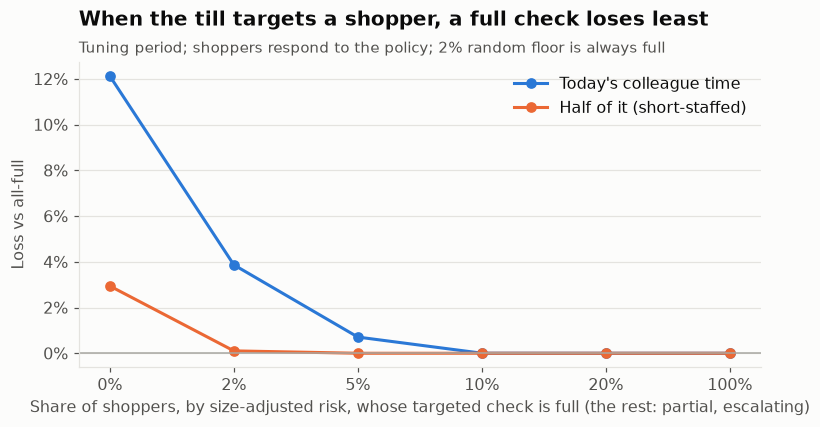

In [2]:
base = {s: tune[tune.colleague_time == s].set_index('full_share') for s in ('today', 'half')}
fig, ax = plt.subplots(figsize=(8, 3.6))
for s, colour, label in (('today', BLUE, "Today's colleague time"),
                         ('half', ORANGE, 'Half of it (short-staffed)')):
    d = base[s]
    rel = d.loss_remaining / d.loss_remaining.loc[1.0] - 1
    x = range(len(rel))
    ax.plot(x, rel.values, marker='o', color=colour, label=label)
ax.set_xticks(range(len(rel)), [f'{v:.0%}' for v in rel.index])
ax.yaxis.set_major_formatter(pct())
ax.axhline(0, color=GREY, lw=1)
ax.set_xlabel('Share of shoppers, by size-adjusted risk, whose targeted check is full '
              '(the rest: partial, escalating)')
ax.set_ylabel('Loss vs all-full')
ax.legend(frameon=False)
ax.set_title('When the till targets a shopper, a full check loses least')
subtitle(ax, 'Tuning period; shoppers respond to the policy; 2% random floor is always full')
save(fig, '26_partial_vs_full')
fig

**Reading it.**

- **Turning targeted checks into partial checks always adds loss.** At today's colleague time,
  making every risk-based check partial leaves about 12% more loss than making them all full; it
  only stops getting worse once at least the top tenth of shoppers by risk get full checks, and
  those are where all the targeted checks go anyway.
- **It holds when short-staffed**, when cheaper partial checks might have been expected to win by
  covering more shoppers.
- **It holds if partial checks were more careful** (finding 97% of picked mistakes rather than
  53%) or checked 25% of the basket instead of 20% (checked separately while building v1.4).
- **Why:** items taken on purpose are usually concealed, and a partial check rarely reaches them;
  it escalates only if the sample happens to contain a slip. A full check of a shopper the model
  has already picked out goes straight to what matters.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Modelled properly (20% of the basket, escalating), today's checks recover about 43% more than 3 fixed items did, for about 18% more colleague time | Today is a stronger baseline; the headline is restated against it |
| 2 | Against it, the recommended policy still cuts loss by about a fifth and stops 58% fewer honest shoppers, with the same colleague time | The conclusion holds |
| 3 | For targeted checks, full beats partial at every mix, on a full and a half-staffed shift, and with more careful partial checks | **v1.4**: the till asks for a full check when it targets; partial checks stay a cheap random courtesy check only if a store wants one |
| 4 | Training labels and the loss estimate use full checks only; an escalated partial check is excluded because the basket was chosen by what the sample found | Unchanged design, now explicit |